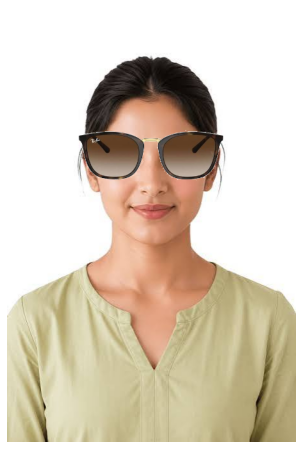

Sunglasses added successfully!


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load images
photo = cv2.imread("girl.jpg")
sunglasses = cv2.imread("sunglass.jpg")

# Check images
if photo is None:
    print("Photo not found. Check girl.jpg")
elif sunglasses is None:
    print("Sunglasses not found. Check sunglass(1).jpg")
else:
    # Crop sunglasses
    sunglasses = sunglasses[165:310, 70:470]

    # Create mask to remove white background
    gray = cv2.cvtColor(sunglasses, cv2.COLOR_BGR2GRAY)
    alpha = np.where(gray < 245, 255, 0).astype(np.uint8)

    # Resize sunglasses
    new_width = 235
    new_height = int(sunglasses.shape[0] * new_width / sunglasses.shape[1])

    sunglasses = cv2.resize(sunglasses, (new_width, new_height))
    alpha = cv2.resize(alpha, (new_width, new_height))

    # Position sunglasses
    x = 108
    y = 190

    h, w = sunglasses.shape[:2]

    # Select eye region
    roi = photo[y:y+h, x:x+w]

    # Blend using alpha mask
    alpha = alpha / 255.0
    alpha = np.stack([alpha] * 3, axis=2)

    result = (alpha * sunglasses + (1 - alpha) * roi).astype(np.uint8)

    photo[y:y+h, x:x+w] = result

    # Save output
    cv2.imwrite("final_sunglasses.jpg", photo)

    # Display output
    plt.figure(figsize=(6, 8))
    plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    print("Sunglasses added successfully!")